<a href="https://colab.research.google.com/github/ChetanyaGarg27/DA-projects/blob/main/Marketing_Spend_Optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Step 1 - Import libraries


In [ ]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import ipywidgets as widgets
from IPython.display import display, HTML

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 50)
pd.options.display.float_format = "{:,.2f}".format
print("Libraries loaded.")

Libraries loaded.


## Step 2 - Load the marketing dataset


In [ ]:
def locate_data():
    candidates = ["marketing_campaign_dataset.csv", "marketing_campaign_dataset.csv.zip"]
    for name in candidates:
        if Path(name).exists():
            return name
    try:  # Google Colab upload dialog
        from google.colab import files
        print("Please upload marketing_campaign_dataset.csv (or the .zip) ...")
        uploaded = files.upload()
        return next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("Put marketing_campaign_dataset.csv (or the .zip) next to this notebook.")

DATA_FILE = locate_data()
df_raw = pd.read_csv(DATA_FILE)   # pandas reads a single-file .zip directly

print(f"File: {DATA_FILE}")
print(f"Shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns\n")
print("Columns:", list(df_raw.columns), "\n")
display(df_raw.head())
print("\nData types:")
print(df_raw.dtypes)

Please upload marketing_campaign_dataset.csv (or the .zip) ...


Saving marketing_campaign_dataset.csv.zip to marketing_campaign_dataset.csv.zip
File: marketing_campaign_dataset.csv.zip
Shape: 200,000 rows × 16 columns

Columns: ['Campaign_ID', 'Company', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Conversion_Rate', 'Acquisition_Cost', 'ROI', 'Location', 'Language', 'Clicks', 'Impressions', 'Engagement_Score', 'Customer_Segment', 'Date'] 



,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
3,4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.11,"$12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
4,5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.05,"$16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05



Data types:
Campaign_ID           int64
Company              object
Campaign_Type        object
Target_Audience      object
Duration             object
Channel_Used         object
Conversion_Rate     float64
Acquisition_Cost     object
ROI                 float64
Location             object
Language             object
Clicks                int64
Impressions           int64
Engagement_Score      int64
Customer_Segment     object
Date                 object
dtype: object


## Step 3 - Data cleaning and preparation


In [ ]:
df = df_raw.copy()
log = []   # (what we checked, what we found, what we did)

# 3.1 Column names -> snake_case, clearer names for the two key columns
df.columns = [re.sub(r"[^0-9a-zA-Z]+", "_", c.strip()).strip("_").lower() for c in df.columns]
df = df.rename(columns={"channel_used": "channel", "acquisition_cost": "campaign_cost"})
log.append(("Column names", "Mixed case, long names", "Converted to snake_case; channel_used→channel, acquisition_cost→campaign_cost"))

# 3.2 Data types
cost_before = df["campaign_cost"].isna().sum()
df["campaign_cost"] = pd.to_numeric(df["campaign_cost"].astype(str).str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce")
df["duration_days"] = pd.to_numeric(df["duration"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
df = df.drop(columns="duration")
df["date"] = pd.to_datetime(df["date"], errors="coerce")
cat_cols = ["company", "campaign_type", "target_audience", "channel", "location", "language", "customer_segment"]
for c in cat_cols:
    df[c] = df[c].astype(str).str.strip()
log.append(("Data types", "campaign_cost was text ('$16,174.00'), duration text ('30 days'), date text",
            "→ float, → integer duration_days, → datetime; category text trimmed"))

# 3.3 Missing values
missing = df.isna().sum()
print("Missing values per column:")
print(missing[missing > 0] if missing.any() else "  none")
core = ["campaign_cost", "roi", "date", "channel"]
rows_before = len(df)
df = df.dropna(subset=core)
for c in df.select_dtypes("number").columns:       # non-core numeric gaps -> median
    df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    df[c] = df[c].replace({"nan": np.nan}).fillna(df[c].mode().iloc[0])
log.append(("Missing values", f"{int(missing.sum())} missing cells",
            f"Dropped {rows_before - len(df)} rows missing a core field (cost/ROI/date/channel); median/mode fill elsewhere" if missing.any() else "None needed"))

# 3.4 Duplicates
dup_rows = int(df.duplicated().sum())
dup_ids = int(df.duplicated("campaign_id").sum())
df = df.drop_duplicates().drop_duplicates("campaign_id")
log.append(("Duplicates", f"{dup_rows} duplicate rows, {dup_ids} repeated campaign_ids", "Removed" if (dup_rows or dup_ids) else "None found"))

# 3.5 Invalid values
bad = pd.concat({
    "campaign_cost <= 0": df["campaign_cost"] <= 0,
    "ROI <= -1 (would mean negative revenue)": df["roi"] <= -1,
    "conversion_rate outside [0, 1]": ~df["conversion_rate"].between(0, 1),
    "clicks > impressions": df["clicks"] > df["impressions"],
    "negative clicks or impressions": (df["clicks"] < 0) | (df["impressions"] < 0),
    "unparseable date": df["date"].isna(),
}, axis=1)
print("\nInvalid-value checks (rows failing):")
print(bad.sum().to_string())
n_bad = int(bad.any(axis=1).sum())
df = df[~bad.any(axis=1)].reset_index(drop=True)
log.append(("Invalid values", f"{n_bad} rows failed {bad.shape[1]} checks (negative/zero cost, negative revenue, bad rates, clicks>impressions)",
            "Removed" if n_bad else "None found - nothing removed"))

# 3.6 Derived columns (assumptions A2 and A3) - these are DERIVED, not observed
df["revenue"] = df["campaign_cost"] * (1 + df["roi"])        # A2
df["conversions"] = df["clicks"] * df["conversion_rate"]     # A3
df["ym"] = df["date"].dt.strftime("%Y-%m")
df["month"] = df["date"].dt.to_period("M").dt.to_timestamp()
log.append(("Derived columns", "No revenue or conversions columns", "revenue = cost×(1+ROI) [A2]; conversions = clicks×conversion_rate [A3]"))

# 3.7 Suitability checks
print("\n--- Suitability checks ---")
print(f"Rows: {len(df):,} | Date range: {df['date'].min().date()} → {df['date'].max().date()} | Channels: {df['channel'].nunique()}")
print("Rows per channel:", df["channel"].value_counts().to_dict())
print("Zero-cost rows:", int((df['campaign_cost'] == 0).sum()), "| Zero-click rows:", int((df['clicks'] == 0).sum()))

# Do the numbers look like real-world data, or like uniformly random draws?
# For each numeric column: largest gap between the observed cumulative share and a perfectly even spread over its distinct values.
print("\nHow close are the numeric columns to an even (uniform) spread over their values? (max CDF gap: smaller = closer; ~0.00 = near-perfect)")
ks_rows = []
for c in ["campaign_cost", "roi", "clicks", "impressions", "conversion_rate", "engagement_score"]:
    vc = df[c].round(4).value_counts().sort_index()
    obs_cdf = vc.cumsum().to_numpy() / vc.sum()
    exp_cdf = np.arange(1, len(vc) + 1) / len(vc)
    ks_rows.append({"column": c, "min": df[c].min(), "max": df[c].max(), "distinct_values": len(vc), "KS_stat": np.abs(obs_cdf - exp_cdf).max()})
ks_table = pd.DataFrame(ks_rows)
display(ks_table)
looks_synthetic = bool((ks_table["KS_stat"] < 0.05).all())   # 0.05 leaves room for 2-decimal rounding at the endpoints
cat_balance = {c: df[c].value_counts(normalize=True).agg(["min", "max"]).round(3).tolist() for c in ["channel", "campaign_type", "company"]}
print("Category share range (min, max):", cat_balance)
if looks_synthetic:
    print("\n⚠ DATA-QUALITY NOTE: every numeric column is almost perfectly uniform and categories are evenly balanced. "
          "That pattern is typical of SIMULATED data, not real campaign logs. We continue (it is a valid practice dataset), "
          "but we must not expect, or claim, real-world channel differences unless the tests show them.")

# 3.8 Cleaned data + change log
print(f"\nCleaned dataset: {len(df):,} rows × {df.shape[1]} columns (started with {len(df_raw):,} × {df_raw.shape[1]})")
display(df.head())
display(pd.DataFrame(log, columns=["Check", "Finding", "Action taken"]))

Missing values per column:
  none

Invalid-value checks (rows failing):
campaign_cost <= 0                         0
ROI <= -1 (would mean negative revenue)    0
conversion_rate outside [0, 1]             0
clicks > impressions                       0
negative clicks or impressions             0
unparseable date                           0

--- Suitability checks ---
Rows: 200,000 | Date range: 2021-01-01 → 2021-12-31 | Channels: 6
Rows per channel: {'Email': 33599, 'Google Ads': 33438, 'YouTube': 33392, 'Instagram': 33392, 'Website': 33360, 'Facebook': 32819}
Zero-cost rows: 0 | Zero-click rows: 0

How close are the numeric columns to an even (uniform) spread over their values? (max CDF gap: smaller = closer; ~0.00 = near-perfect)


,column,min,max,distinct_values,KS_stat
0,campaign_cost,"5,000.00","20,000.00",15001,0.00
1,roi,2.00,8.00,601,0.00
2,clicks,100.00,"1,000.00",901,0.00
3,impressions,"1,000.00","10,000.00",9001,0.00
4,conversion_rate,0.01,0.15,15,0.03
5,engagement_score,1.00,10.00,10,0.00


Category share range (min, max): {'channel': [0.164, 0.168], 'campaign_type': [0.199, 0.201], 'company': [0.199, 0.201]}

⚠ DATA-QUALITY NOTE: every numeric column is almost perfectly uniform and categories are evenly balanced. That pattern is typical of SIMULATED data, not real campaign logs. We continue (it is a valid practice dataset), but we must not expect, or claim, real-world channel differences unless the tests show them.

Cleaned dataset: 200,000 rows × 20 columns (started with 200,000 × 16)


,campaign_id,company,campaign_type,target_audience,channel,conversion_rate,campaign_cost,roi,location,language,clicks,impressions,engagement_score,customer_segment,date,duration_days,revenue,conversions,ym,month
0,1,Innovate Industries,Email,Men 18-24,Google Ads,0.04,"16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01,30,"117,908.46",20.24,2021-01,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,Google Ads,0.12,"11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02,60,"76,451.26",13.92,2021-01,2021-01-01
2,3,Alpha Innovations,Influencer,Men 25-34,YouTube,0.07,"10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03,30,"83,436.00",40.88,2021-01,2021-01-01
3,4,DataTech Solutions,Display,All Ages,YouTube,0.11,"12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04,60,"83,342.20",23.87,2021-01,2021-01-01
4,5,NexGen Systems,Email,Men 25-34,YouTube,0.05,"16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05,15,"123,390.00",18.95,2021-01,2021-01-01


,Check,Finding,Action taken
0,Column names,"Mixed case, long names","Converted to snake_case; channel_used→channel,..."
1,Data types,"campaign_cost was text ('$16,174.00'), duratio...","→ float, → integer duration_days, → datetime; ..."
2,Missing values,0 missing cells,None needed
3,Duplicates,"0 duplicate rows, 0 repeated campaign_ids",None found
4,Invalid values,"0 rows failed 6 checks (negative/zero cost, ne...",None found - nothing removed
5,Derived columns,No revenue or conversions columns,revenue = cost×(1+ROI) [A2]; conversions = cli...


## Step 4 - Exploratory Data Analysis (EDA)


Descriptive statistics (numeric):


,count,mean,std,min,25%,50%,75%,max
campaign_cost,"200,000.00","12,504.39","4,337.66","5,000.00","8,739.75","12,496.50","16,264.00","20,000.00"
revenue,"200,000.00","75,091.34","34,799.24","15,071.07","47,728.08","68,814.84","98,146.36","179,438.36"
roi,"200,000.00",5.00,1.73,2.00,3.50,5.01,6.51,8.00
clicks,"200,000.00",549.77,260.02,100.00,325.00,550.00,775.00,"1,000.00"
impressions,"200,000.00","5,507.30","2,596.86","1,000.00","3,266.00","5,517.50","7,753.00","10,000.00"
conversion_rate,"200,000.00",0.08,0.04,0.01,0.05,0.08,0.12,0.15
conversions,"200,000.00",44.02,32.32,1.00,17.76,35.76,64.10,150.00
engagement_score,"200,000.00",5.49,2.87,1.00,3.00,5.00,8.00,10.00
duration_days,"200,000.00",37.50,16.75,15.00,30.00,30.00,45.00,60.00



Category counts:
  channel: {'Email': 33599, 'Google Ads': 33438, 'YouTube': 33392, 'Instagram': 33392, 'Website': 33360, 'Facebook': 32819}
  campaign_type: {'Influencer': 40169, 'Search': 40157, 'Display': 39987, 'Email': 39870, 'Social Media': 39817}
  company: {'TechCorp': 40237, 'Alpha Innovations': 40051, 'DataTech Solutions': 40012, 'NexGen Systems': 39991, 'Innovate Industries': 39709}


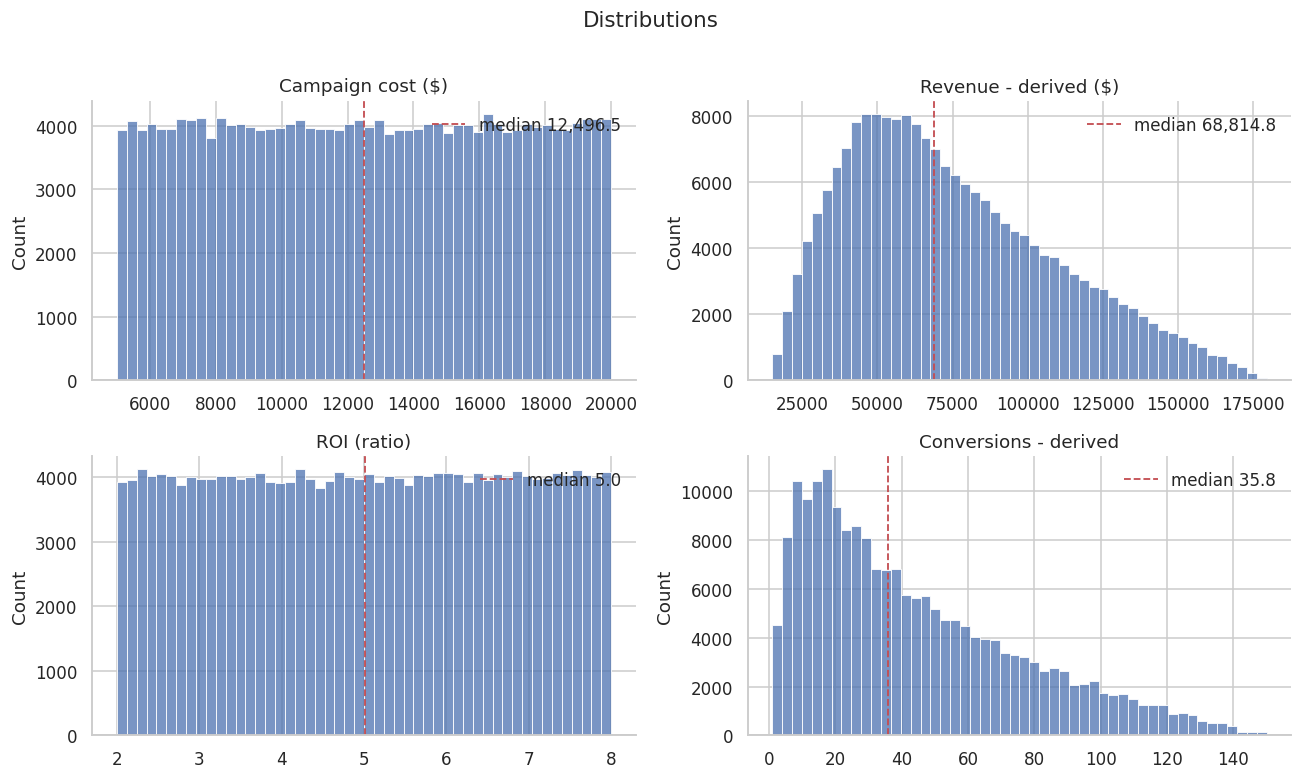

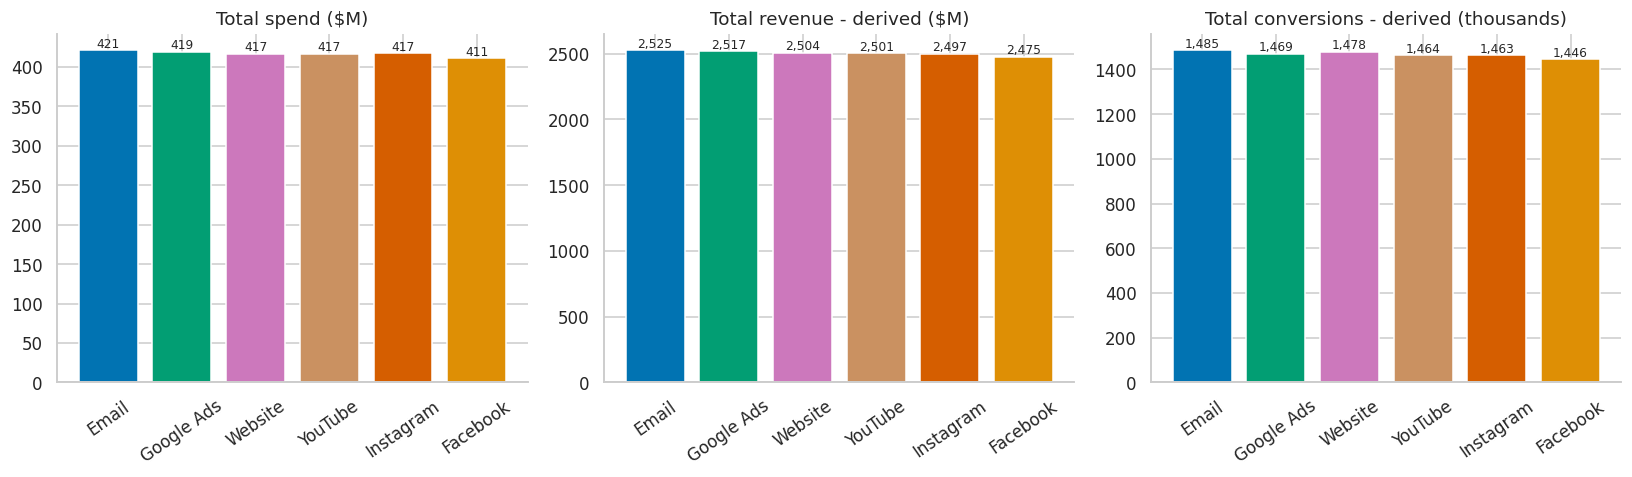

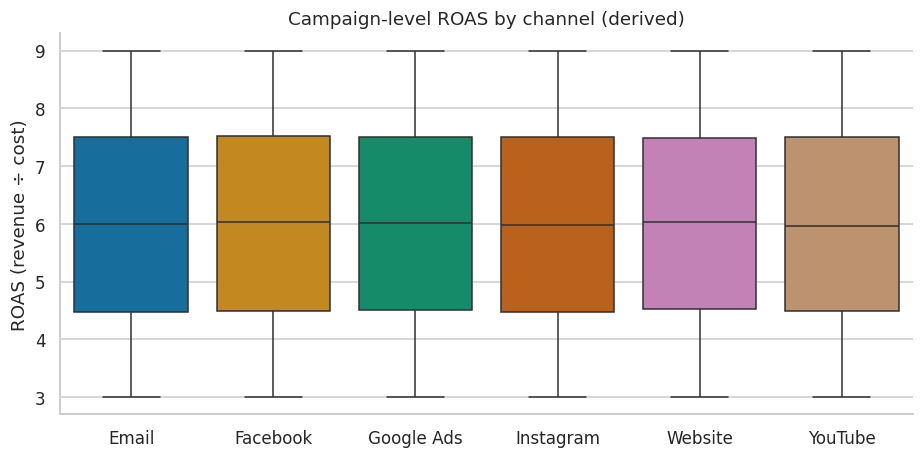

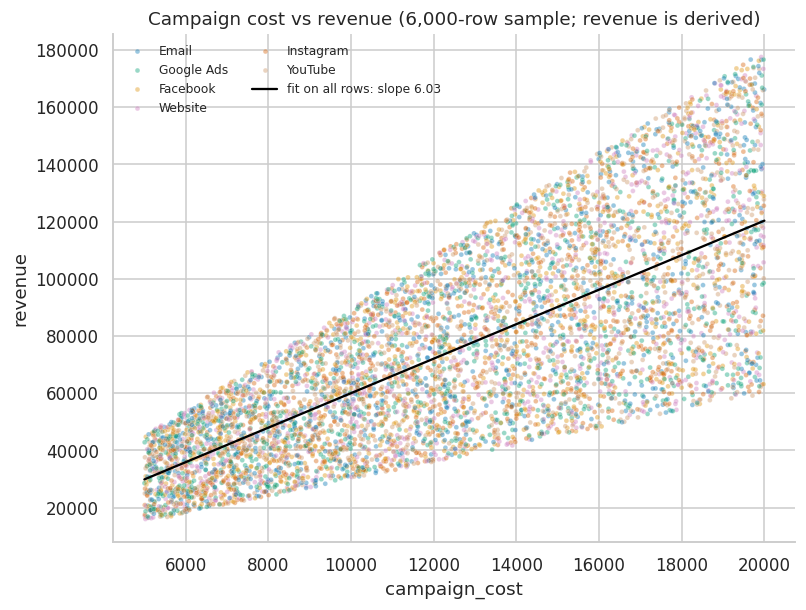

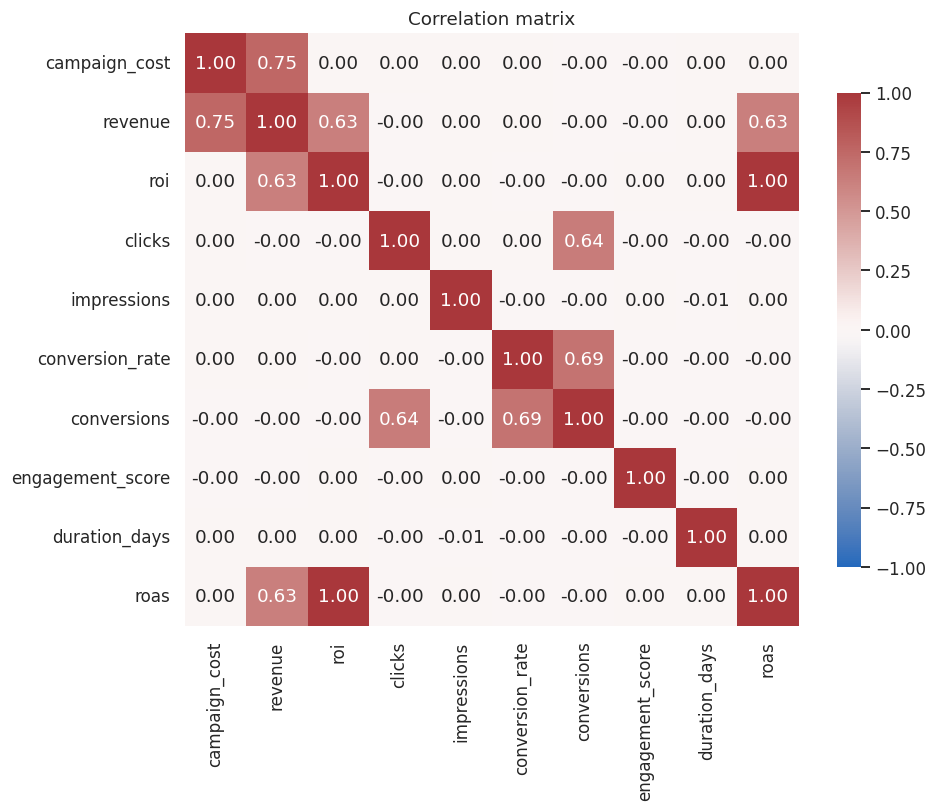

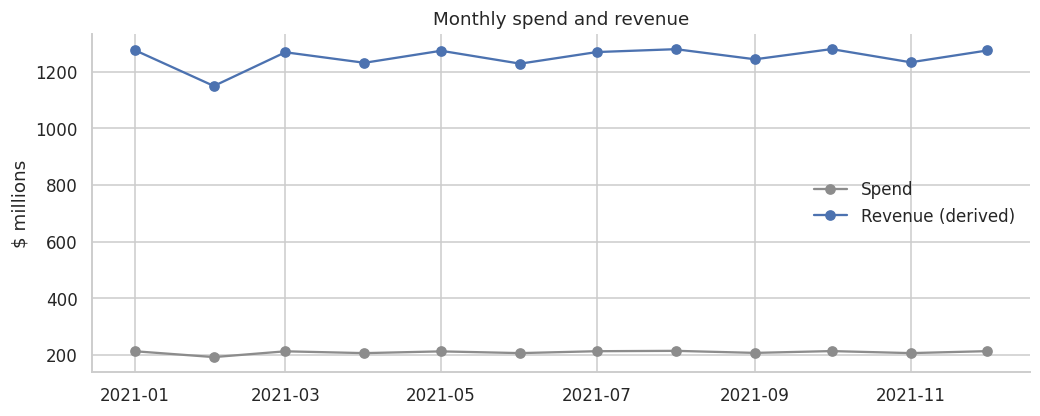

EDA takeaways (computed from the data):
  • corr(cost, revenue) = 0.75  - high, but revenue was built from cost (A2), so this is partly mechanical
  • corr(cost, ROI)     = 0.005 - i.e. spending more is NOT linked to a better return
  • corr(clicks, impressions) = 0.000; corr(engagement, ROI) = 0.001
  • Channel share of spend ranges only 16.4% - 16.8%


In [ ]:
CHANNELS = sorted(df["channel"].unique())
CH_COLOR = dict(zip(CHANNELS, sns.color_palette("colorblind", len(CHANNELS)).as_hex()))
df["roas"] = df["revenue"] / df["campaign_cost"]    # needed for EDA; formally defined in Step 5

# 4.1 Descriptive statistics
eda_cols = ["campaign_cost", "revenue", "roi", "clicks", "impressions", "conversion_rate", "conversions", "engagement_score", "duration_days"]
print("Descriptive statistics (numeric):")
display(df[eda_cols].describe().T)
print("\nCategory counts:")
for c in ["channel", "campaign_type", "company"]:
    print(f"  {c}: {df[c].value_counts().to_dict()}")

# 4.2 Distributions of spend and revenue
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (col, title) in zip(axes.ravel(), [("campaign_cost", "Campaign cost ($)"), ("revenue", "Revenue - derived ($)"),
                                           ("roi", "ROI (ratio)"), ("conversions", "Conversions - derived")]):
    sns.histplot(df[col], bins=50, color="#4C72B0", ax=ax)
    ax.axvline(df[col].median(), color="#C44E52", ls="--", lw=1.2, label=f"median {df[col].median():,.1f}")
    ax.set_title(title); ax.set_xlabel(""); ax.legend(frameon=False)
fig.suptitle("Distributions", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

# 4.3 Channel comparison: spend, revenue, conversions
agg = df.groupby("channel").agg(spend=("campaign_cost", "sum"), revenue=("revenue", "sum"),
                                conversions=("conversions", "sum"), campaigns=("campaign_id", "count")).sort_values("revenue", ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, title, div, fmt) in zip(axes, [("spend", "Total spend ($M)", 1e6, "{:,.0f}"), ("revenue", "Total revenue - derived ($M)", 1e6, "{:,.0f}"),
                                             ("conversions", "Total conversions - derived (thousands)", 1e3, "{:,.0f}")]):
    vals = agg[col] / div
    ax.bar(agg.index, vals, color=[CH_COLOR[c] for c in agg.index])
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=8)
    ax.set_title(title); ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

# 4.4 ROAS spread by channel
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df, x="channel", y="roas", order=CHANNELS, hue="channel", palette=CH_COLOR, legend=False, fliersize=1, ax=ax)
ax.set_title("Campaign-level ROAS by channel (derived)"); ax.set_xlabel(""); ax.set_ylabel("ROAS (revenue ÷ cost)")
plt.show()

# 4.5 Spend vs revenue
sample = df.sample(6000, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=sample, x="campaign_cost", y="revenue", hue="channel", palette=CH_COLOR, s=10, alpha=0.4, ax=ax)
slope, intercept = np.polyfit(df["campaign_cost"], df["revenue"], 1)
xs = np.linspace(df["campaign_cost"].min(), df["campaign_cost"].max(), 50)
ax.plot(xs, intercept + slope * xs, color="black", lw=1.5, label=f"fit on all rows: slope {slope:.2f}")
ax.set_title("Campaign cost vs revenue (6,000-row sample; revenue is derived)"); ax.legend(frameon=False, fontsize=8, ncol=2)
plt.show()

# 4.6 Correlations
corr = df[eda_cols + ["roas"]].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix"); plt.show()

# 4.7 Monthly trend
monthly = df.groupby("month").agg(spend=("campaign_cost", "sum"), revenue=("revenue", "sum"), conversions=("conversions", "sum"))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly["spend"] / 1e6, marker="o", color="#8C8C8C", label="Spend")
ax.plot(monthly.index, monthly["revenue"] / 1e6, marker="o", color="#4C72B0", label="Revenue (derived)")
ax.set_ylabel("$ millions"); ax.set_title("Monthly spend and revenue"); ax.legend(frameon=False)
plt.show()

print("EDA takeaways (computed from the data):")
print(f"  • corr(cost, revenue) = {corr.loc['campaign_cost', 'revenue']:.2f}  - high, but revenue was built from cost (A2), so this is partly mechanical")
print(f"  • corr(cost, ROI)     = {corr.loc['campaign_cost', 'roi']:.3f} - i.e. spending more is NOT linked to a better return")
print(f"  • corr(clicks, impressions) = {corr.loc['clicks', 'impressions']:.3f}; corr(engagement, ROI) = {corr.loc['engagement_score', 'roi']:.3f}")
print(f"  • Channel share of spend ranges only {agg['spend'].min() / agg['spend'].sum():.1%} - {agg['spend'].max() / agg['spend'].sum():.1%}")

## Step 5 - Calculate ROI and ROAS


In [ ]:
def safe_div(num, den):
    """num/den; zero or missing denominators give NaN instead of inf/errors."""
    if hasattr(den, "replace"):
        den = den.replace(0, np.nan)
    elif den == 0:
        den = np.nan
    out = num / den
    return out.replace([np.inf, -np.inf], np.nan) if hasattr(out, "replace") else out

# Campaign level
df["roas"] = safe_div(df["revenue"], df["campaign_cost"])
df["roi_pct"] = safe_div(df["revenue"] - df["campaign_cost"], df["campaign_cost"]) * 100
df["cpa"] = safe_div(df["campaign_cost"], df["conversions"])
df["cpc"] = safe_div(df["campaign_cost"], df["clicks"])
df["ctr_pct"] = safe_div(df["clicks"], df["impressions"]) * 100

# Sanity checks of the identities implied by A2/A4
print("ROAS == 1 + ROI (original):", np.allclose(df["roas"], 1 + df["roi"]))
print("ROI% == ROI(original) × 100:", np.allclose(df["roi_pct"], df["roi"] * 100))
print("Rows with NaN ROAS/CPA after safe division:", int(df["roas"].isna().sum()), "/", int(df["cpa"].isna().sum()))

def fmt3(frame, cols):
    """Display copy with 3 decimals for ratio columns (the global 2-decimal format hides small channel gaps)."""
    out = frame.copy()
    for c in cols:
        out[c] = out[c].map("{:.3f}".format)
    return out

def summarize(frame, by):
    """Aggregate to any level and compute spend-weighted metrics from sums."""
    g = frame.groupby(by).agg(campaigns=("campaign_id", "count"), spend=("campaign_cost", "sum"), revenue=("revenue", "sum"),
                              conversions=("conversions", "sum"), clicks=("clicks", "sum"), impressions=("impressions", "sum"),
                              mean_campaign_roi=("roi", "mean"))
    g["roas"] = safe_div(g["revenue"], g["spend"])
    g["roi_pct"] = safe_div(g["revenue"] - g["spend"], g["spend"]) * 100
    g["cpa"] = safe_div(g["spend"], g["conversions"])
    g["cpc"] = safe_div(g["spend"], g["clicks"])
    g["ctr_pct"] = safe_div(g["clicks"], g["impressions"]) * 100
    g["cvr_pct"] = safe_div(g["conversions"], g["clicks"]) * 100
    g["spend_share_pct"] = g["spend"] / g["spend"].sum() * 100
    g["revenue_share_pct"] = g["revenue"] / g["revenue"].sum() * 100
    return g

print("\nCampaign-level metrics (first rows):")
display(df[["campaign_id", "channel", "campaign_cost", "revenue", "roas", "roi_pct", "conversions", "cpa"]].head())
print("\nChannel-level metrics:")
chan = summarize(df, "channel")
display(fmt3(chan[["campaigns", "spend", "revenue", "conversions", "roas", "roi_pct", "cpa", "ctr_pct", "cvr_pct"]], ["roas"]))
print("\nCampaign-type-level metrics:")
display(summarize(df, "campaign_type")[["campaigns", "spend", "revenue", "conversions", "roas", "roi_pct", "cpa"]])

ROAS == 1 + ROI (original): True
ROI% == ROI(original) × 100: True
Rows with NaN ROAS/CPA after safe division: 0 / 0

Campaign-level metrics (first rows):


,campaign_id,channel,campaign_cost,revenue,roas,roi_pct,conversions,cpa
0,1,Google Ads,"16,174.00","117,908.46",7.29,629.00,20.24,799.11
1,2,Google Ads,"11,566.00","76,451.26",6.61,561.00,13.92,830.89
2,3,YouTube,"10,200.00","83,436.00",8.18,718.00,40.88,249.51
3,4,YouTube,"12,724.00","83,342.20",6.55,555.00,23.87,533.05
4,5,YouTube,"16,452.00","123,390.00",7.50,650.00,18.95,868.18



Channel-level metrics:


,campaigns,spend,revenue,conversions,roas,roi_pct,cpa,ctr_pct,cvr_pct
channel,,,,,,,,,
Email,33599,"420,874,104.00","2,524,644,207.68","1,485,393.65",5.999,499.86,283.34,10.01,8.03
Facebook,32819,"410,595,258.00","2,474,540,725.41","1,446,290.30",6.027,502.67,283.90,9.98,8.02
Google Ads,33438,"418,912,314.00","2,516,723,624.98","1,468,753.09",6.008,500.78,285.22,9.91,8.01
Instagram,33392,"417,124,850.00","2,497,101,378.70","1,462,864.48",5.986,498.65,285.14,9.97,7.99
Website,33360,"416,593,500.00","2,504,152,455.56","1,477,710.16",6.011,501.10,281.92,10.02,8.02
YouTube,33392,"416,778,582.00","2,501,104,889.91","1,463,568.01",6.001,500.10,284.77,10.00,7.98



Campaign-type-level metrics:


,campaigns,spend,revenue,conversions,roas,roi_pct,cpa
campaign_type,,,,,,,
Display,39987,"500,158,774.00","3,004,994,743.40","1,763,752.74",6.01,500.81,283.58
Email,39870,"498,189,449.00","2,989,230,432.33","1,746,961.36",6.00,500.02,285.17
Influencer,40169,"502,400,525.00","3,021,351,330.36","1,771,218.18",6.01,501.38,283.65
Search,40157,"501,911,760.00","3,016,515,383.52","1,764,203.50",6.01,501.01,284.50
Social Media,39817,"498,218,100.00","2,986,175,392.63","1,758,443.91",5.99,499.37,283.33


## Step 6 - Channel performance analysis


Do channels differ in ROAS?  ANOVA p = 0.171 | Kruskal-Wallis p = 0.172 | effect size η² = 0.00004


,spend,revenue,conversions,roas,roas_lo,roas_hi,roi_pct,cpa,rank_roas,rank_cpa,rank_conversions,spend_share_pct,revenue_share_pct,status
channel,,,,,,,,,,,,,,
Facebook,"410,595,258.00","2,474,540,725.41","1,446,290.30",6.027,6.006,6.047,502.67,283.90,1,3,6,16.42,16.48,In line with average (no significant channel d...
Website,"416,593,500.00","2,504,152,455.56","1,477,710.16",6.011,5.991,6.030,501.10,281.92,2,1,2,16.66,16.67,In line with average (no significant channel d...
Google Ads,"418,912,314.00","2,516,723,624.98","1,468,753.09",6.008,5.988,6.026,500.78,285.22,3,6,3,16.75,16.76,In line with average (no significant channel d...
YouTube,"416,778,582.00","2,501,104,889.91","1,463,568.01",6.001,5.981,6.021,500.10,284.77,4,4,4,16.67,16.65,In line with average (no significant channel d...
Email,"420,874,104.00","2,524,644,207.68","1,485,393.65",5.999,5.977,6.018,499.86,283.34,5,2,1,16.83,16.81,In line with average (no significant channel d...
Instagram,"417,124,850.00","2,497,101,378.70","1,462,864.48",5.986,5.965,6.006,498.65,285.14,6,5,5,16.68,16.63,In line with average (no significant channel d...



Portfolio ROAS = 6.005x | Portfolio CPA = $284.0
Best vs worst channel ROAS: Facebook 6.027x vs Instagram 5.986x (gap 0.040x = 0.67% of the average)


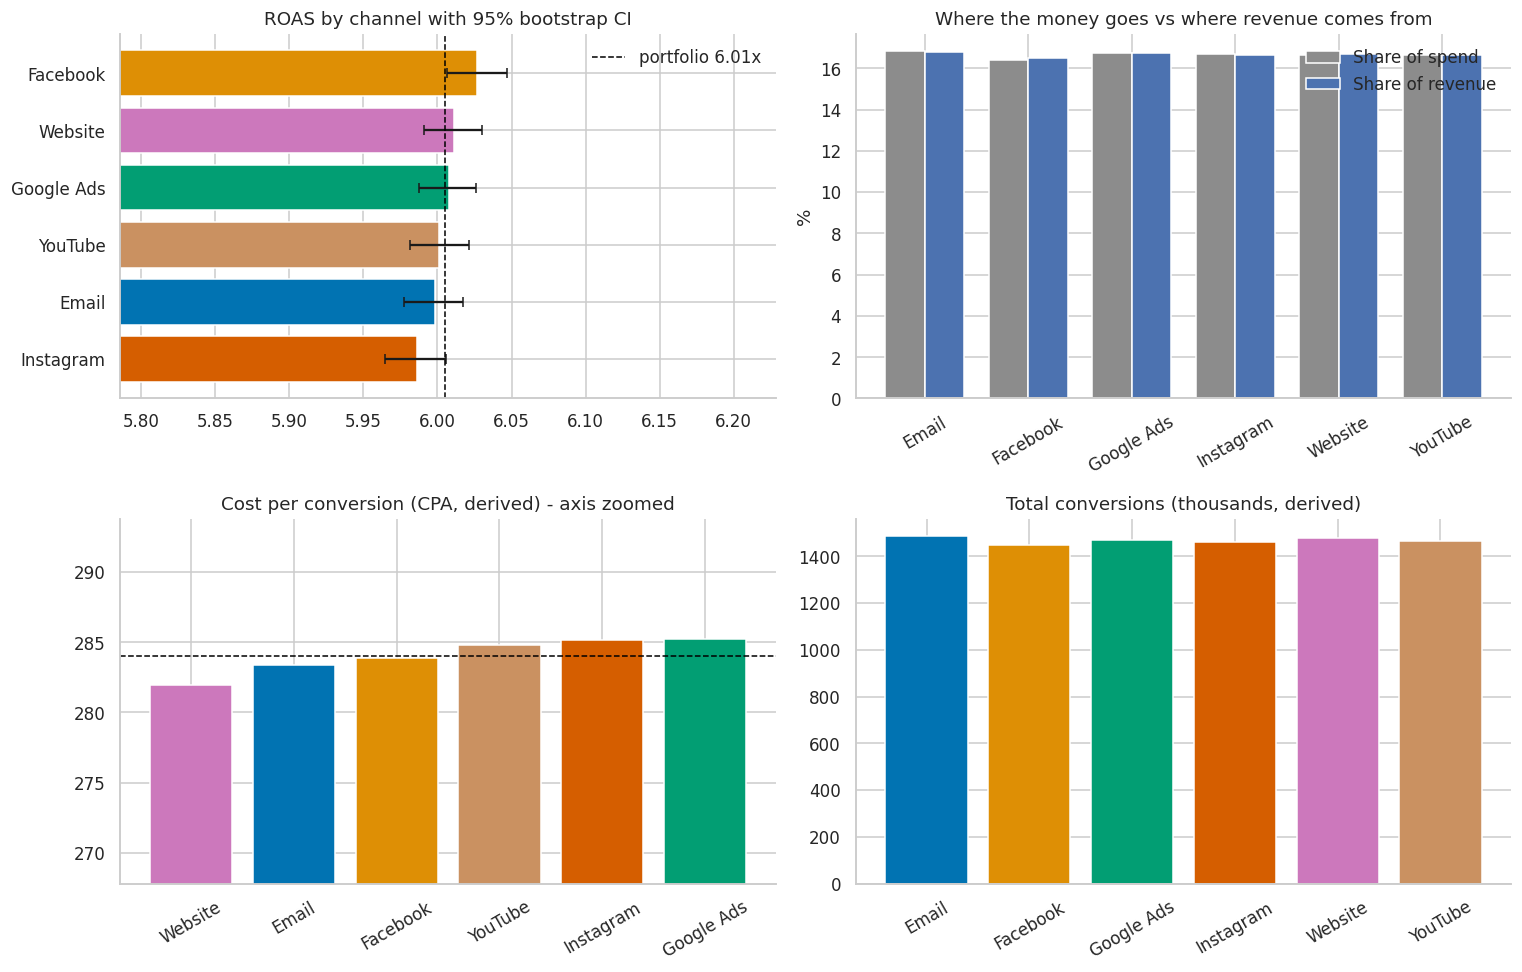

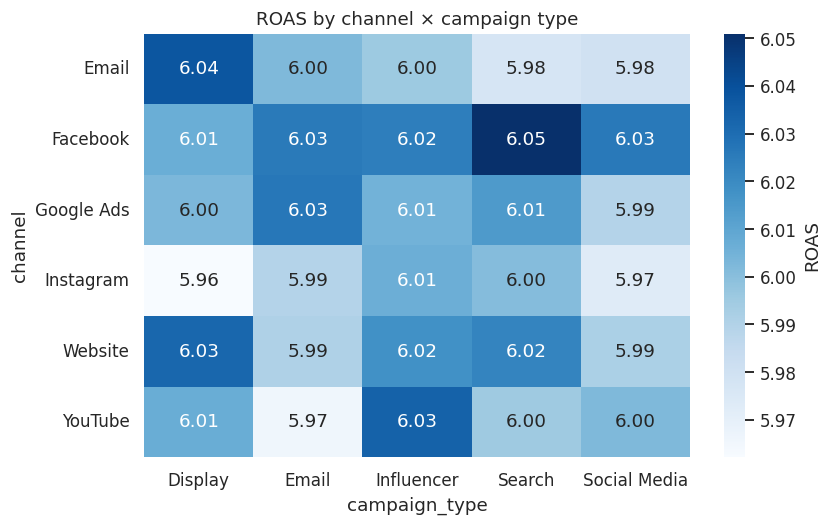

Cell range: 5.96x to 6.05x. With ~6,666 campaigns per cell, differences of this size are typically within sampling noise.


In [ ]:
overall_roas = df["revenue"].sum() / df["campaign_cost"].sum()
overall_cpa = df["campaign_cost"].sum() / df["conversions"].sum()

def boot_ratio(frame, B=1000, seed=SEED):
    """Bootstrap distribution of spend-weighted ROAS (resample campaigns with replacement)."""
    rng = np.random.default_rng(seed)
    c, r = frame["campaign_cost"].to_numpy(), frame["revenue"].to_numpy()
    n = len(c)
    out = np.empty(B)
    for b in range(B):
        i = rng.integers(0, n, n)
        out[b] = r[i].sum() / c[i].sum()
    return out

boot = {ch: boot_ratio(g, seed=SEED + k) for k, (ch, g) in enumerate(df.groupby("channel"))}
chan["roas_lo"] = [np.percentile(boot[c], 2.5) for c in chan.index]
chan["roas_hi"] = [np.percentile(boot[c], 97.5) for c in chan.index]

# Overall tests: do channels differ at all?
groups = [g["roas"].to_numpy() for _, g in df.groupby("channel")]
F, p_anova = stats.f_oneway(*groups)
H, p_kw = stats.kruskal(*groups)
grand = df["roas"].mean()
eta_sq = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / ((df["roas"] - grand) ** 2).sum()
print(f"Do channels differ in ROAS?  ANOVA p = {p_anova:.3f} | Kruskal-Wallis p = {p_kw:.3f} | effect size η² = {eta_sq:.5f}")
omnibus_sig = (p_anova < 0.05) and (p_kw < 0.05)

def status_of(ch):
    if not omnibus_sig:
        return "In line with average (no significant channel differences)"
    if chan.loc[ch, "roas_lo"] > overall_roas:
        return "High-performing (significantly above average)"
    if chan.loc[ch, "roas_hi"] < overall_roas:
        return "Inefficient (significantly below average)"
    return "In line with average"

chan["status"] = [status_of(c) for c in chan.index]
chan["rank_roas"] = chan["roas"].rank(ascending=False).astype(int)
chan["rank_cpa"] = chan["cpa"].rank(ascending=True).astype(int)
chan["rank_conversions"] = chan["conversions"].rank(ascending=False).astype(int)
chan["spend_minus_revenue_share_pp"] = chan["spend_share_pct"] - chan["revenue_share_pct"]

table6 = chan.sort_values("roas", ascending=False)[["spend", "revenue", "conversions", "roas", "roas_lo", "roas_hi", "roi_pct", "cpa",
                                                    "rank_roas", "rank_cpa", "rank_conversions", "spend_share_pct", "revenue_share_pct", "status"]]
display(fmt3(table6, ["roas", "roas_lo", "roas_hi"]))
print(f"\nPortfolio ROAS = {overall_roas:.3f}x | Portfolio CPA = ${overall_cpa:,.1f}")
spread = chan["roas"].max() - chan["roas"].min()
print(f"Best vs worst channel ROAS: {chan['roas'].idxmax()} {chan['roas'].max():.3f}x vs {chan['roas'].idxmin()} {chan['roas'].min():.3f}x "
      f"(gap {spread:.3f}x = {spread / overall_roas:.2%} of the average)")

# Charts
order = chan.sort_values("roas").index
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
ax = axes[0, 0]
ax.barh(order, chan.loc[order, "roas"], color=[CH_COLOR[c] for c in order],
        xerr=[chan.loc[order, "roas"] - chan.loc[order, "roas_lo"], chan.loc[order, "roas_hi"] - chan.loc[order, "roas"]], capsize=3)
ax.axvline(overall_roas, color="black", ls="--", lw=1, label=f"portfolio {overall_roas:.2f}x")
ax.set_xlim(chan["roas_lo"].min() * 0.97, chan["roas_hi"].max() * 1.03)
ax.set_title("ROAS by channel with 95% bootstrap CI"); ax.legend(frameon=False)

ax = axes[0, 1]
x = np.arange(len(chan)); w = 0.38
ax.bar(x - w / 2, chan["spend_share_pct"], w, color="#8C8C8C", label="Share of spend")
ax.bar(x + w / 2, chan["revenue_share_pct"], w, color="#4C72B0", label="Share of revenue")
ax.set_xticks(x); ax.set_xticklabels(chan.index, rotation=30); ax.set_ylabel("%")
ax.set_title("Where the money goes vs where revenue comes from"); ax.legend(frameon=False)

ax = axes[1, 0]
o2 = chan.sort_values("cpa").index
ax.bar(o2, chan.loc[o2, "cpa"], color=[CH_COLOR[c] for c in o2])
ax.axhline(overall_cpa, color="black", ls="--", lw=1)
ax.set_ylim(chan["cpa"].min() * 0.95, chan["cpa"].max() * 1.03)   # zoomed axis - note the truncated baseline
ax.set_title("Cost per conversion (CPA, derived) - axis zoomed"); ax.tick_params(axis="x", rotation=30)

ax = axes[1, 1]
ax.bar(chan.index, chan["conversions"] / 1e3, color=[CH_COLOR[c] for c in chan.index])
ax.set_title("Total conversions (thousands, derived)"); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

# Channel x campaign-type view (is any combination special?)
cc = df.groupby(["channel", "campaign_type"]).apply(lambda g: g["revenue"].sum() / g["campaign_cost"].sum()).unstack()
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(cc, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar_kws={"label": "ROAS"})
ax.set_title("ROAS by channel × campaign type")
plt.show()
print(f"Cell range: {cc.min().min():.2f}x to {cc.max().max():.2f}x. With ~{len(df) // cc.size:,} campaigns per cell, differences of this size are typically within sampling noise.")

## Step 7 - Regression analysis


Train: 160,000 rows | Test: 40,000 rows


,R² (test),MAE ($),RMSE ($),R² (train)
model,,,,
Baseline: predict the mean,-0.00,"28,535.31","34,750.96",0.00
Linear: cost only,0.56,"18,784.22","22,957.43",0.57
Linear: all features,0.56,"18,786.49","22,960.52",0.57
Gradient boosting: all features,0.56,"18,801.45","22,992.08",0.57


Best on test RMSE: Linear: cost only

Cost-only model: revenue ≈ -390 + 6.035 × cost
  → each extra $1 of campaign cost is associated with ≈ $6.04 of additional (derived) revenue, close to the portfolio ROAS of 6.01x. This equals ROAS by construction (A2); it is not independent proof.


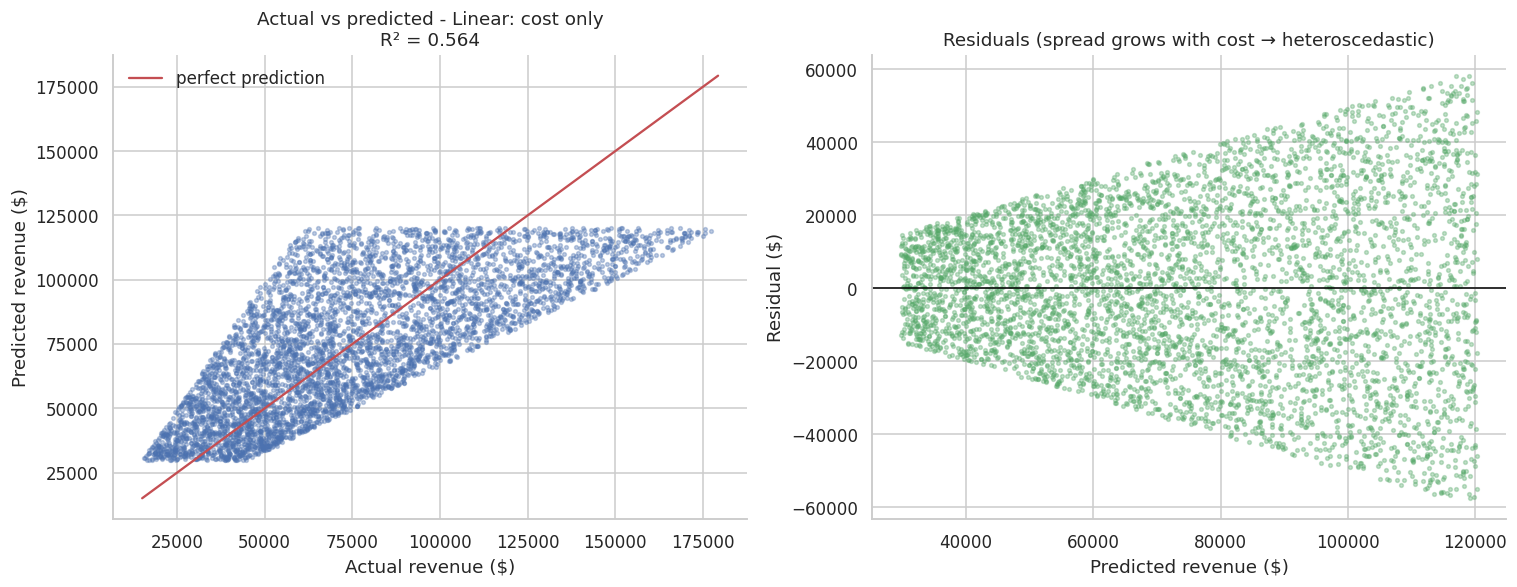


Permutation importance (increase in RMSE, $, when a feature is shuffled):


,importance
campaign_cost,"21,013.94"
impressions,20.70
conversion_rate,17.69
engagement_score,-2.10
duration_days,-3.66
channel,-3.70
campaign_type,-4.89
clicks,-36.72



Channel-level cost→revenue slopes:


,slope ($ revenue per $1 cost),95% CI low,95% CI high,R²
channel,,,,
Email,6.02,5.96,6.08,0.56
Facebook,6.09,6.03,6.15,0.57
Google Ads,6.05,5.99,6.10,0.57
Instagram,5.98,5.92,6.03,0.56
Website,6.00,5.95,6.06,0.57
YouTube,6.06,6.00,6.11,0.57



Model B (predict ROI from ALL other columns): R² (test) = -0.0005 | MAE = 1.503 ROI points (baseline MAE of always guessing the mean = 1.503)
→ No column (cost, channel, audience, location, engagement, …) explains ROI. Performance differences look like noise.

Saved test_predictions.csv


In [ ]:
num_feats = ["campaign_cost", "clicks", "impressions", "conversion_rate", "engagement_score", "duration_days"]
cat_feats = ["channel", "campaign_type"]
X = df[num_feats + cat_feats]
y = df["revenue"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")

def make_pipe(model, num, cat):
    transformers = [("num", "passthrough", num)]
    if cat:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat))
    return Pipeline([("prep", ColumnTransformer(transformers)), ("model", model)])

specs = {
    "Baseline: predict the mean": make_pipe(DummyRegressor(), ["campaign_cost"], []),
    "Linear: cost only": make_pipe(LinearRegression(), ["campaign_cost"], []),
    "Linear: all features": make_pipe(LinearRegression(), num_feats, cat_feats),
    "Gradient boosting: all features": make_pipe(HistGradientBoostingRegressor(random_state=SEED), num_feats, cat_feats),
}
fitted, rows = {}, []
for name, pipe in specs.items():
    pipe.fit(X_train, y_train)
    pred_te, pred_tr = pipe.predict(X_test), pipe.predict(X_train)
    fitted[name] = pipe
    rows.append({"model": name, "R² (test)": r2_score(y_test, pred_te), "MAE ($)": mean_absolute_error(y_test, pred_te),
                 "RMSE ($)": np.sqrt(mean_squared_error(y_test, pred_te)), "R² (train)": r2_score(y_train, pred_tr)})
results = pd.DataFrame(rows).set_index("model")
display(results)

best_name = results.drop(index="Baseline: predict the mean")["RMSE ($)"].idxmin()
best_model = fitted[best_name]
print(f"Best on test RMSE: {best_name}")

# Interpretation of the simplest model
lin = fitted["Linear: cost only"].named_steps["model"]
print(f"\nCost-only model: revenue ≈ {lin.intercept_:,.0f} + {lin.coef_[0]:.3f} × cost")
print(f"  → each extra $1 of campaign cost is associated with ≈ ${lin.coef_[0]:.2f} of additional (derived) revenue, "
      f"close to the portfolio ROAS of {overall_roas:.2f}x. This equals ROAS by construction (A2); it is not independent proof.")

# Actual vs predicted + residuals
pred_best = best_model.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
idx = np.random.default_rng(SEED).choice(len(y_test), 5000, replace=False)
axes[0].scatter(y_test.to_numpy()[idx], pred_best[idx], s=6, alpha=0.35, color="#4C72B0")
lims = [y_test.min(), y_test.max()]
axes[0].plot(lims, lims, color="#C44E52", lw=1.5, label="perfect prediction")
axes[0].set_xlabel("Actual revenue ($)"); axes[0].set_ylabel("Predicted revenue ($)")
axes[0].set_title(f"Actual vs predicted - {best_name}\nR² = {r2_score(y_test, pred_best):.3f}"); axes[0].legend(frameon=False)
resid = y_test.to_numpy() - pred_best
axes[1].scatter(pred_best[idx], resid[idx], s=6, alpha=0.35, color="#55A868")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xlabel("Predicted revenue ($)"); axes[1].set_ylabel("Residual ($)"); axes[1].set_title("Residuals (spread grows with cost → heteroscedastic)")
plt.tight_layout(); plt.show()

# Which inputs matter? (permutation importance on the boosting model)
gb = fitted["Gradient boosting: all features"]
samp = X_test.sample(5000, random_state=SEED)
pi = permutation_importance(gb, samp, y_test.loc[samp.index], n_repeats=3, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
print("\nPermutation importance (increase in RMSE, $, when a feature is shuffled):")
display(imp.to_frame("importance"))

# Do channels differ in how revenue responds to cost?
slope_rows = []
for ch, g in df.groupby("channel"):
    r = stats.linregress(g["campaign_cost"], g["revenue"])
    slope_rows.append({"channel": ch, "slope ($ revenue per $1 cost)": r.slope, "95% CI low": r.slope - 1.96 * r.stderr,
                       "95% CI high": r.slope + 1.96 * r.stderr, "R²": r.rvalue ** 2})
slopes = pd.DataFrame(slope_rows).set_index("channel")
print("\nChannel-level cost→revenue slopes:")
display(slopes)

# MODEL B - the non-circular test: can ROI be predicted from anything?
b_num = ["campaign_cost", "clicks", "impressions", "conversion_rate", "engagement_score", "duration_days"]
b_cat = ["channel", "campaign_type", "company", "target_audience", "location", "language", "customer_segment"]
XB_tr, XB_te, yB_tr, yB_te = train_test_split(df[b_num + b_cat], df["roi"], test_size=0.2, random_state=SEED)
model_b = make_pipe(HistGradientBoostingRegressor(random_state=SEED), b_num, b_cat).fit(XB_tr, yB_tr)
pB = model_b.predict(XB_te)
r2_b = r2_score(yB_te, pB)
print(f"\nModel B (predict ROI from ALL other columns): R² (test) = {r2_b:.4f} | MAE = {mean_absolute_error(yB_te, pB):.3f} ROI points "
      f"(baseline MAE of always guessing the mean = {mean_absolute_error(yB_te, np.full(len(yB_te), yB_tr.mean())):.3f})")
if r2_b < 0.01:
    print("→ No column (cost, channel, audience, location, engagement, …) explains ROI. Performance differences look like noise.")

# Save outputs for the dashboard
test_df = df.loc[X_test.index, ["campaign_id", "channel", "campaign_type", "company", "date", "revenue"]].copy()
test_df["pred_revenue"] = pred_best
test_df.to_csv("test_predictions.csv", index=False)
print("\nSaved test_predictions.csv")

## Step 8 - Interactive dashboard


In [ ]:
df["roas"] = safe_div(df["revenue"], df["campaign_cost"])
MONTHS = sorted(df["ym"].unique())
CAMPAIGN_TYPES = sorted(df["campaign_type"].unique())
COMPANIES = sorted(df["company"].unique())
test_df["ym"] = test_df["date"].dt.strftime("%Y-%m")

def filter_data(frame, channels, types, companies, m_lo, m_hi):
    return frame[frame["channel"].isin(channels) & frame["campaign_type"].isin(types) & frame["company"].isin(companies)
                 & (frame["ym"] >= m_lo) & (frame["ym"] <= m_hi)]

def kpi_html(f):
    spend, rev = f["campaign_cost"].sum(), f["revenue"].sum()
    cards = [
        ("Total marketing spend", f"${spend / 1e6:,.1f}M", ""),
        ("Total revenue (derived)", f"${rev / 1e6:,.1f}M", ""),
        ("Overall ROAS", f"{rev / spend:.2f}x", f"mean campaign ROAS {f['roas'].mean():.2f}x"),
        ("Overall ROI", f"{(rev - spend) / spend * 100:,.0f}%", "based on total campaign cost"),
        ("Conversions (derived)", f"{f['conversions'].sum():,.0f}", f"CPA ${spend / f['conversions'].sum():,.0f}"),
        ("Campaigns", f"{len(f):,}", ""),
    ]
    html = "<div style='display:flex;gap:12px;flex-wrap:wrap;margin:8px 0'>"
    for title, value, sub in cards:
        html += (f"<div style='flex:1;min-width:150px;padding:12px 14px;border:1px solid rgba(128,128,128,.35);border-radius:10px;"
                 f"background:rgba(128,128,128,.08)'><div style='font-size:12px;opacity:.7'>{title}</div>"
                 f"<div style='font-size:24px;font-weight:600'>{value}</div><div style='font-size:11px;opacity:.65'>{sub}&nbsp;</div></div>")
    return html + "</div>"

def render_dashboard(channels, types, companies, month_range):
    f = filter_data(df, channels, types, companies, *month_range)
    if f.empty:
        display(HTML("<b>No campaigns match the current filters.</b>"))
        return
    display(HTML(kpi_html(f)))
    ch = summarize(f, "channel")
    colors = [CH_COLOR[c] for c in ch.index]

    fig1 = go.Figure()
    fig1.add_bar(x=ch.index, y=ch["spend"] / 1e6, name="Spend ($M)", marker_color="#8C8C8C")
    fig1.add_bar(x=ch.index, y=ch["revenue"] / 1e6, name="Revenue ($M, derived)", marker_color="#4C72B0")
    fig1.update_layout(title="Spend vs revenue by channel", barmode="group", template="plotly_white", height=380, yaxis_title="$ millions")
    fig1.show()

    fig2 = make_subplots(rows=1, cols=2, subplot_titles=("ROAS by channel", "ROI % by channel"))
    fig2.add_bar(x=ch.index, y=ch["roas"], marker_color=colors, text=ch["roas"].round(2), textposition="outside", row=1, col=1)
    fig2.add_bar(x=ch.index, y=ch["roi_pct"], marker_color=colors, text=ch["roi_pct"].round(0), textposition="outside", row=1, col=2)
    fig2.update_layout(template="plotly_white", height=380, showlegend=False)
    fig2.show()

    trend = f.groupby(["ym", "channel"], as_index=False)["conversions"].sum()
    fig3 = px.line(trend, x="ym", y="conversions", color="channel", color_discrete_map=CH_COLOR, markers=True,
                   title="Monthly conversions by channel (derived)", template="plotly_white", height=380)
    fig3.update_layout(xaxis_title="", yaxis_title="Conversions")
    fig3.show()

    ct = summarize(f, "campaign_type").reset_index()
    fig4 = px.bar(ct, x="campaign_type", y="roas", text=ct["roas"].round(2), title="ROAS by campaign type",
                  template="plotly_white", height=340, color_discrete_sequence=["#4C72B0"])
    fig4.update_layout(xaxis_title="", yaxis_title="ROAS")
    fig4.show()
    print("Top 10 campaigns by revenue in the current selection:")
    display(f.nlargest(10, "revenue")[["campaign_id", "company", "campaign_type", "channel", "campaign_cost", "revenue", "roas", "conversions"]].round(2))

    t = filter_data(test_df, channels, types, companies, *month_range)
    if len(t) > 20:
        ts = t.sample(min(3000, len(t)), random_state=SEED)
        r2 = r2_score(t["revenue"], t["pred_revenue"])
        fig5 = px.scatter(ts, x="revenue", y="pred_revenue", color="channel", color_discrete_map=CH_COLOR, opacity=0.5,
                          title=f"Actual vs predicted revenue (held-out test rows: {len(t):,}; R² = {r2:.3f})", template="plotly_white", height=420)
        lim = [float(t["revenue"].min()), float(t["revenue"].max())]
        fig5.add_trace(go.Scatter(x=lim, y=lim, mode="lines", line=dict(color="black", dash="dash"), name="perfect"))
        fig5.update_layout(xaxis_title="Actual revenue ($)", yaxis_title="Predicted revenue ($)")
        fig5.show()

w_channel = widgets.SelectMultiple(options=CHANNELS, value=tuple(CHANNELS), description="Channel", rows=6, layout=widgets.Layout(width="250px"))
w_type = widgets.SelectMultiple(options=CAMPAIGN_TYPES, value=tuple(CAMPAIGN_TYPES), description="Campaign", rows=5, layout=widgets.Layout(width="250px"))
w_company = widgets.SelectMultiple(options=COMPANIES, value=tuple(COMPANIES), description="Company", rows=5, layout=widgets.Layout(width="250px"))
w_months = widgets.SelectionRangeSlider(options=MONTHS, index=(0, len(MONTHS) - 1), description="Months", layout=widgets.Layout(width="520px"))

controls = widgets.HBox([w_channel, w_type, w_company, w_months])
dash_out = widgets.interactive_output(render_dashboard, {"channels": w_channel, "types": w_type, "companies": w_company, "month_range": w_months})
print("Tip: Ctrl/Cmd-click to select several channels, campaign types or companies.")
display(controls, dash_out)

Tip: Ctrl/Cmd-click to select several channels, campaign types or companies.


Output()

## Step 9 - Budget optimization and recommendations


Screening 8 dimensions × 2 metrics; Bonferroni threshold α = 0.0031


,metric,dimension,groups,p_value,eta_sq,best_group,best_mean,worst_group,worst_mean,significant
3,roi,target_audience,5,0.0375,5.09e-05,Men 25-34,5.02,Men 18-24,4.98,False
4,roi,location,5,0.0583,4.56e-05,Miami,5.01,New York,4.98,False
0,roi,channel,6,0.171,3.87e-05,Facebook,5.02,Instagram,4.99,False
10,conversion_rate,company,5,0.246,2.72e-05,Innovate Industries,0.08,NexGen Systems,0.08,False
1,roi,campaign_type,5,0.397,2.03e-05,Influencer,5.01,Social Media,4.99,False
14,conversion_rate,customer_segment,5,0.463,1.80e-05,Foodies,0.08,Fashionistas,0.08,False
9,conversion_rate,campaign_type,5,0.47,1.77e-05,Influencer,0.08,Email,0.08,False
5,roi,language,5,0.521,1.61e-05,French,5.01,English,4.99,False
7,roi,duration_days,4,0.595,9.46e-06,30,5.01,15,5.00,False
2,roi,company,5,0.695,1.11e-05,TechCorp,5.01,NexGen Systems,4.99,False


→ 0 of 16 tests significant after correction.
  (Uncorrected, 1 tests have p < 0.05. With 16 tests, about 0.8 such results are expected by chance alone, which is why we correct.)


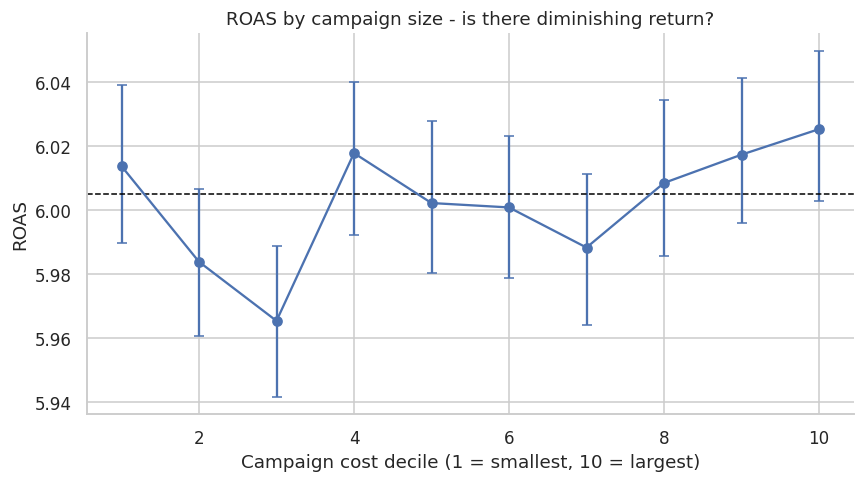

Spearman correlation between campaign cost and ROAS: ρ = 0.0046 (p = 0.041)
→ The correlation is statistically detectable (huge sample) but negligible in size (|ρ| < 0.05) and positive, so there is NO sign of diminishing returns; the constant-ROAS assumption below is not contradicted. (Caveat: this compares different campaigns, not one campaign at several budgets.)
Observed best-vs-worst ROAS gap: 0.040x | typical gap if channels were identical (median of 1,000 shuffles): 0.025x | permutation p = 0.051
→ Borderline: the gap is slightly larger than usual chance variation but does not reach significance, and the gap itself is tiny in business terms. Treat it as a hypothesis to test, not a finding.
What-if: move budget from Instagram (ROAS 5.986x) to Facebook (ROAS 6.027x)
ASSUMPTIONS: (1) the average ROAS also applies to the extra dollars (constant marginal return), not verified by an experiment; (2) the intervals below ignore that best/worst were chosen after the fact, so treat them as 

,shift (% of worst channel's budget),budget moved ($M),est. revenue change ($M),95% CI low ($M),95% CI high ($M),as % of total revenue,naive CI includes zero?
0,5,20.86,0.84,0.27,1.43,0.01,False
1,10,41.71,1.68,0.54,2.85,0.01,False
2,20,83.42,3.36,1.09,5.71,0.02,False


,current_spend_$M,observed_ROAS,observed_ROI_%,CPA_$,conversions_k,recommended_action,rationale
channel,,,,,,,
Facebook,410.60,6.027,502.67,283.90,"1,446.29",Hold current budget,"ROAS 6.03x (95% CI 6.01-6.05) vs portfolio 6.01x; CPA $284 vs $284; spend share 16.4% vs revenue share 16.5%. Channel differences are not statistically significant (ANOVA/Kruskal p > 0.05), so no ..."
Website,416.59,6.011,501.10,281.92,"1,477.71",Hold current budget,"ROAS 6.01x (95% CI 5.99-6.03) vs portfolio 6.01x; CPA $282 vs $284; spend share 16.7% vs revenue share 16.7%. Channel differences are not statistically significant (ANOVA/Kruskal p > 0.05), so no ..."
Google Ads,418.91,6.008,500.78,285.22,"1,468.75",Hold current budget,"ROAS 6.01x (95% CI 5.99-6.03) vs portfolio 6.01x; CPA $285 vs $284; spend share 16.8% vs revenue share 16.8%. Channel differences are not statistically significant (ANOVA/Kruskal p > 0.05), so no ..."
YouTube,416.78,6.001,500.10,284.77,"1,463.57",Hold current budget,"ROAS 6.00x (95% CI 5.98-6.02) vs portfolio 6.01x; CPA $285 vs $284; spend share 16.7% vs revenue share 16.7%. Channel differences are not statistically significant (ANOVA/Kruskal p > 0.05), so no ..."
Email,420.87,5.999,499.86,283.34,"1,485.39",Hold current budget,"ROAS 6.00x (95% CI 5.98-6.02) vs portfolio 6.01x; CPA $283 vs $284; spend share 16.8% vs revenue share 16.8%. Channel differences are not statistically significant (ANOVA/Kruskal p > 0.05), so no ..."
Instagram,417.12,5.986,498.65,285.14,"1,462.86",Hold current budget,"ROAS 5.99x (95% CI 5.96-6.01) vs portfolio 6.01x; CPA $285 vs $284; spend share 16.7% vs revenue share 16.6%. Channel differences are not statistically significant (ANOVA/Kruskal p > 0.05), so no ..."



=== Evidence-based conclusion ===
The data do NOT support reallocating budget between channels. There are no statistically significant ROAS differences between channels (ANOVA p = 0.17, best-vs-worst permutation p = 0.051), no audience/location/company/duration factor is a significant lever after multiple-testing correction, and ROI cannot be predicted from any available column.
Even taken at face value, shifting 10% of Instagram's budget to Facebook would add about $1.7M, only 0.01% of total revenue.
Recommended next step: run a controlled incrementality test (geo or holdout) on one channel before moving money; and pull real revenue/ad-spend data, because this file's revenue is derived and its numbers look simulated.


In [ ]:
# 9.1 Screen for any real performance lever (Bonferroni-corrected for the number of tests)
dims = ["channel", "campaign_type", "company", "target_audience", "location", "language", "customer_segment", "duration_days"]
metrics = ["roi", "conversion_rate"]
alpha = 0.05 / (len(dims) * len(metrics))
rows = []
for metric in metrics:
    grand = df[metric].mean(); sst = ((df[metric] - grand) ** 2).sum()
    for d in dims:
        grp = [g[metric].to_numpy() for _, g in df.groupby(d)]
        Fv, pv = stats.f_oneway(*grp)
        ssb = sum(len(g) * (g.mean() - grand) ** 2 for g in grp)
        gm = df.groupby(d)[metric].mean()
        rows.append({"metric": metric, "dimension": d, "groups": len(grp), "p_value": pv, "eta_sq": ssb / sst,
                     "best_group": gm.idxmax(), "best_mean": gm.max(), "worst_group": gm.idxmin(), "worst_mean": gm.min(), "significant": pv < alpha})
lever = pd.DataFrame(rows).sort_values("p_value")
lever["p_value"] = lever["p_value"].map("{:.3g}".format)
lever["eta_sq"] = lever["eta_sq"].map("{:.2e}".format)
print(f"Screening {len(dims)} dimensions × {len(metrics)} metrics; Bonferroni threshold α = {alpha:.4f}")
display(lever)
n_sig = int(lever["significant"].sum())
print(f"→ {n_sig} of {len(lever)} tests significant after correction.")
print(f"  (Uncorrected, {int((pd.to_numeric(lever['p_value']) < 0.05).sum())} tests have p < 0.05. With {len(lever)} tests, about {0.05 * len(lever):.1f} such results are expected by chance alone, which is why we correct.)")

# 9.2 Diminishing returns check (across campaigns)
df["cost_decile"] = pd.qcut(df["campaign_cost"], 10, labels=False) + 1
dec_rows = []
for k, g in df.groupby("cost_decile"):
    b = boot_ratio(g, B=300, seed=SEED + int(k))
    dec_rows.append({"cost_decile": k, "avg_cost": g["campaign_cost"].mean(), "roas": g["revenue"].sum() / g["campaign_cost"].sum(),
                     "lo": np.percentile(b, 2.5), "hi": np.percentile(b, 97.5)})
dec = pd.DataFrame(dec_rows)
rho, p_rho = stats.spearmanr(df["campaign_cost"], df["roas"])
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(dec["cost_decile"], dec["roas"], yerr=[dec["roas"] - dec["lo"], dec["hi"] - dec["roas"]], fmt="o-", color="#4C72B0", capsize=3)
ax.axhline(overall_roas, color="black", ls="--", lw=1)
ax.set_xlabel("Campaign cost decile (1 = smallest, 10 = largest)"); ax.set_ylabel("ROAS")
ax.set_title("ROAS by campaign size - is there diminishing return?")
plt.show()
diminishing = (p_rho < 0.05) and (rho < -0.05)
print(f"Spearman correlation between campaign cost and ROAS: ρ = {rho:.4f} (p = {p_rho:.3f})")
if diminishing:
    print("→ ROAS falls as campaigns get bigger: evidence of diminishing returns.")
elif p_rho < 0.05:
    print(f"→ The correlation is statistically detectable (huge sample) but negligible in size (|ρ| < 0.05) and positive, so there is NO sign of diminishing returns; "
          "the constant-ROAS assumption below is not contradicted. (Caveat: this compares different campaigns, not one campaign at several budgets.)")
else:
    print("→ No relationship between campaign size and ROAS; the constant-ROAS assumption below is not contradicted. "
          "(Caveat: this compares different campaigns, not one campaign at several budgets.)")

# 9.3 What-if: move budget from the lowest-ROAS to the highest-ROAS channel
best_ch, worst_ch = chan["roas"].idxmax(), chan["roas"].idxmin()

# Selection caveat: we picked best/worst AFTER seeing results among 6 channels, so a naive CI for their gap is too optimistic.
# Permutation test: shuffle channel labels (a world where channels truly do not differ) and see how big a best-vs-worst gap arises by chance.
codes, _ = pd.factorize(df["channel"])
c_arr, r_arr = df["campaign_cost"].to_numpy(), df["revenue"].to_numpy()
def roas_gap(labels):
    r = np.bincount(labels, weights=r_arr) / np.bincount(labels, weights=c_arr)
    return r.max() - r.min()
obs_gap = roas_gap(codes)
rng_perm = np.random.default_rng(SEED)
null_gaps = np.array([roas_gap(rng_perm.permutation(codes)) for _ in range(1000)])
p_perm = (np.sum(null_gaps >= obs_gap) + 1) / (len(null_gaps) + 1)
perm_sig = p_perm < 0.05
print(f"Observed best-vs-worst ROAS gap: {obs_gap:.3f}x | typical gap if channels were identical (median of 1,000 shuffles): {np.median(null_gaps):.3f}x "
      f"| permutation p = {p_perm:.3f}")
if perm_sig:
    print("→ The gap is larger than chance would produce.")
elif p_perm < 0.10:
    print("→ Borderline: the gap is slightly larger than usual chance variation but does not reach significance, and the gap itself is tiny in business terms. "
          "Treat it as a hypothesis to test, not a finding.")
else:
    print("→ A gap this large is ordinary chance: the 'best' and 'worst' channels are not reliably different.")
whatif = []
for shift in [5, 10, 20]:
    moved = chan.loc[worst_ch, "spend"] * shift / 100
    point = moved * (chan.loc[best_ch, "roas"] - chan.loc[worst_ch, "roas"])
    draws = moved * (boot[best_ch] - boot[worst_ch])
    lo, hi = np.percentile(draws, [2.5, 97.5])
    whatif.append({"shift (% of worst channel's budget)": shift, "budget moved ($M)": moved / 1e6, "est. revenue change ($M)": point / 1e6,
                   "95% CI low ($M)": lo / 1e6, "95% CI high ($M)": hi / 1e6, "as % of total revenue": point / df["revenue"].sum() * 100,
                   "naive CI includes zero?": bool(lo <= 0 <= hi)})
whatif = pd.DataFrame(whatif)
print(f"What-if: move budget from {worst_ch} (ROAS {chan.loc[worst_ch, 'roas']:.3f}x) to {best_ch} (ROAS {chan.loc[best_ch, 'roas']:.3f}x)")
print("ASSUMPTIONS: (1) the average ROAS also applies to the extra dollars (constant marginal return), not verified by an experiment; "
      "(2) the intervals below ignore that best/worst were chosen after the fact, so treat them as optimistic when the permutation p above is not small.")
display(whatif)

# 9.4 Final recommendation table
def recommend(ch):
    s = chan.loc[ch, "status"]
    if s.startswith("High"):
        return "Increase (+10% as a controlled test)"
    if s.startswith("Inefficient"):
        return "Decrease (−10%) and review"
    return "Hold current budget"

def rationale(ch):
    r = chan.loc[ch]
    base = (f"ROAS {r['roas']:.2f}x (95% CI {r['roas_lo']:.2f}-{r['roas_hi']:.2f}) vs portfolio {overall_roas:.2f}x; "
            f"CPA ${r['cpa']:,.0f} vs ${overall_cpa:,.0f}; spend share {r['spend_share_pct']:.1f}% vs revenue share {r['revenue_share_pct']:.1f}%. ")
    if not omnibus_sig:
        return base + "Channel differences are not statistically significant (ANOVA/Kruskal p > 0.05), so no evidence supports shifting budget."
    return base + "Overall test is significant; this channel's interval " + ("excludes" if not chan.loc[ch, "status"].startswith("In line") else "overlaps") + " the average."

final = pd.DataFrame({
    "current_spend_$M": chan["spend"] / 1e6,
    "observed_ROAS": chan["roas"],
    "observed_ROI_%": chan["roi_pct"],
    "CPA_$": chan["cpa"],
    "conversions_k": chan["conversions"] / 1e3,
    "recommended_action": [recommend(c) for c in chan.index],
    "rationale": [rationale(c) for c in chan.index],
}).sort_values("observed_ROAS", ascending=False)
pd.set_option("display.max_colwidth", 200)
display(fmt3(final, ["observed_ROAS"]))

print("\n=== Evidence-based conclusion ===")
if (not omnibus_sig) and (not perm_sig) and n_sig == 0 and r2_b < 0.01:
    ten = whatif.loc[whatif.iloc[:, 0] == 10].iloc[0]
    print("The data do NOT support reallocating budget between channels. There are no statistically significant ROAS differences between channels "
          f"(ANOVA p = {p_anova:.2f}, best-vs-worst permutation p = {p_perm:.3f}), no audience/location/company/duration factor is a significant lever "
          "after multiple-testing correction, and ROI cannot be predicted from any available column.")
    print(f"Even taken at face value, shifting 10% of {worst_ch}'s budget to {best_ch} would add about ${ten['est. revenue change ($M)']:.1f}M, "
          f"only {ten['as % of total revenue']:.2f}% of total revenue.")
    print("Recommended next step: run a controlled incrementality test (geo or holdout) on one channel before moving money; "
          "and pull real revenue/ad-spend data, because this file's revenue is derived and its numbers look simulated.")
else:
    print("Some differences are statistically significant. Follow the 'recommended_action' column, start with the small controlled shifts, and re-check with a holdout test.")